# 00 · Environment setup

## Purpose

Confirm the local Python environment and the dependencies needed by the ReturnWise research sequence.

## Method

Inspect versions and optional package availability without installing packages or accessing credentials from inside the notebook. Set up the named kernel using the documented terminal command.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

Dependency presence does not prove that a later model can train on this machine. Resource and compatibility checks happen again at experiment time.

## References

See the environment setup steps in README.md.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '00 · Environment setup')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 00 · Environment setup


,package,version,importable
0,streamlit,1.66.1,True
1,pandas,3.1.0,True
2,numpy,2.5.4,True
3,scipy,1.18.1,True
4,scikit-learn,1.9.1,True
5,kaggle,not installed,False
6,ipykernel,7.4.0,True
7,catboost,not installed,False
8,lightgbm,not installed,False
9,xgboost,not installed,False


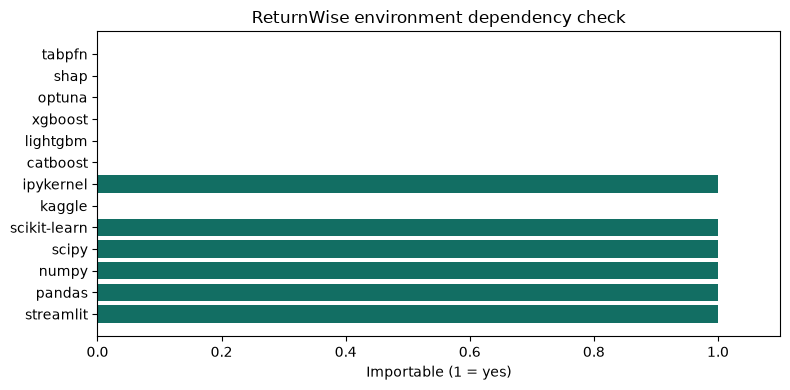

Kernel install command (run in the activated project environment if needed):
python -m ipykernel install --user --name returnwise --display-name "Python (ReturnWise)"
Experiment mode saved for the notebook sequence: quick


In [2]:
import importlib.metadata as metadata
import importlib.util
import matplotlib.pyplot as plt
import pandas as pd

packages = ['streamlit', 'pandas', 'numpy', 'scipy', 'scikit-learn', 'kaggle', 'ipykernel',
            'catboost', 'lightgbm', 'xgboost', 'optuna', 'shap', 'tabpfn']
rows = []
for package in packages:
    try:
        version = metadata.version(package)
    except metadata.PackageNotFoundError:
        version = 'not installed'
    module_name = {'scikit-learn': 'sklearn'}.get(package, package.replace('-', '_'))
    rows.append({'package': package, 'version': version, 'importable': importlib.util.find_spec(module_name) is not None})
environment = pd.DataFrame(rows)
display(environment)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(environment['package'], environment['importable'].astype(int), color='#126E63')
ax.set_xlim(0, 1.1)
ax.set_xlabel('Importable (1 = yes)')
ax.set_title('ReturnWise environment dependency check')
plt.tight_layout()
plt.show()
print('Kernel install command (run in the activated project environment if needed):')
print('python -m ipykernel install --user --name returnwise --display-name "Python (ReturnWise)"')
EXPERIMENT_MODE = 'quick'  # Change to 'full' for five-fold runs and the larger Optuna budget.
state['experiment_mode'] = EXPERIMENT_MODE
save_state(state)
print('Experiment mode saved for the notebook sequence:', EXPERIMENT_MODE)
